Перші 5 рядків:
   advertising  discount   sales
0        15.48     22.10  811.98
1         8.78     26.59  404.43
2        17.17     27.63  968.80
3        13.95     15.11  675.62
4         1.88     15.61  147.59

Розмір набору даних: (500, 3)

Пропущені значення:
advertising    0
discount       0
sales          0
dtype: int64

Описова статистика:
       advertising    discount        sales
count   500.000000  500.000000   500.000000
mean      9.913680   14.960240   476.233240
std       5.735295    8.897955   294.498361
min       0.110000    0.040000   -28.790000
25%       4.717500    7.300000   206.822500
50%      10.015000   14.810000   431.755000
75%      14.947500   22.902500   708.625000
max      19.980000   29.960000  1220.450000

Навчальна вибірка: 400 записів
Тестова вибірка: 100 записів
MAE: 9.240264895845709
R²: 0.9985439762058353
MSE:  141.09792128777647
RMSE:  11.87846460144477


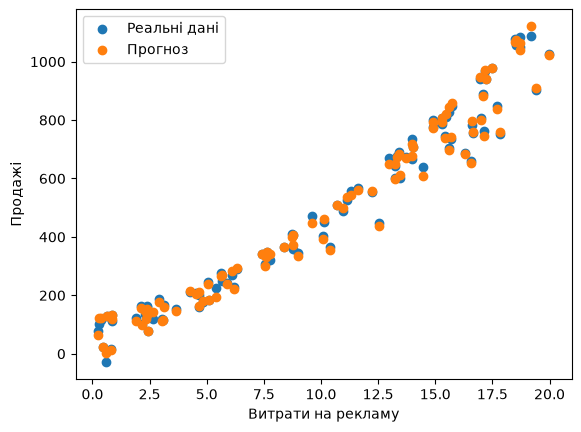

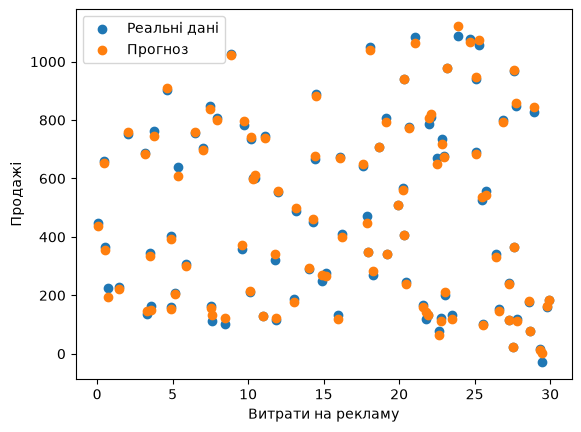

In [17]:
# import numpy as np
# import pandas as pd
# # Для відтворюваності результатів
# rng = np.random.default_rng(42)
# # Кількість записів
# n = 500
# # Генеруємо дві вхідні ознаки
# advertising = rng.uniform(0, 20, n)
# discount = rng.uniform(0, 30, n)
# # Випадковий шум
# noise = rng.normal(0, 12, n)
# # Поліном другого порядку
# sales = (
#     100
#     + 8 * advertising
#     + 5 * discount
#     + 1.5 * advertising**2
#     - 0.3 * discount**2
#     + 0.8 * advertising * discount
#     + noise
# )
# # Створюємо DataFrame
# df = pd.DataFrame({
#     "advertising": advertising,
#     "discount": discount,
#     "sales": sales
# })
# print(df)


# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.linear_model import LinearRegression
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, root_mean_squared_error

# # Завантажуємо дані
# df = pd.read_csv("polynomial_sales_500.csv")

# # Одна вхідна ознака
# X = df[["advertising"]]

# # Цільова змінна
# y = df["sales"]

# # Розділяємо дані на навчальні та тестові
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# # Навчаємо модель
# model = LinearRegression()
# model.fit(X_train, y_train)

# # Прогнозуємо продажі
# y_pred = model.predict(X_test)

# print("Коефіцієнт w:", model.coef_[0])
# print("Вільний член b:", model.intercept_)
# print("MAE:", mean_absolute_error(y_test, y_pred))
# print("R²:", r2_score(y_test, y_pred))
# print("MSE: ", mean_squared_error(y_test, y_pred))
# print("RMSE: ",root_mean_squared_error(y_test, y_pred))

# # Графік
# plt.scatter(X_test["advertising"], y_test, label="Реальні дані")
# plt.scatter(X_test["advertising"], y_pred, label="Прогноз")
# plt.xlabel("Витрати на рекламу")
# plt.ylabel("Продажі")
# plt.legend()
# plt.show()

# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.linear_model import LinearRegression
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, root_mean_squared_error

# # Завантажуємо дані
# df = pd.read_csv("polynomial_sales_500.csv")

# # Одна вхідна ознака
# X = df[["discount"]]

# # Цільова змінна
# y = df["sales"]

# # Розділяємо дані на навчальні та тестові
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# # Навчаємо модель
# model = LinearRegression()
# model.fit(X_train, y_train)

# # Прогнозуємо продажі
# y_pred = model.predict(X_test)

# print("Коефіцієнт w:", model.coef_[0])
# print("Вільний член b:", model.intercept_)
# print("MAE:", mean_absolute_error(y_test, y_pred))
# print("R²:", r2_score(y_test, y_pred))
# print("MSE: ", mean_squared_error(y_test, y_pred))
# print("RMSE: ",root_mean_squared_error(y_test, y_pred))

# # Графік
# plt.scatter(X_test["discount"], y_test, label="Реальні дані")
# plt.scatter(X_test["discount"], y_pred, label="Прогноз")
# plt.xlabel("Витрати на рекламу")
# plt.ylabel("Продажі")
# plt.legend()
# plt.show()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    median_absolute_error,
    max_error,
    explained_variance_score
)

# ------------------------------------------------------------
# 1. Завантаження даних
# ------------------------------------------------------------

df = pd.read_csv("polynomial_sales_500.csv")

print("Перші 5 рядків:")
print(df.head())

print("\nРозмір набору даних:", df.shape)
print("\nПропущені значення:")
print(df.isnull().sum())
print("\nОписова статистика:")
print(df.describe())

# Перевірка та видалення пропущених значень
df = df.dropna(subset=["advertising", "discount", "sales"])

X = df[["advertising", "discount"]]
y = df["sales"]

# ------------------------------------------------------------
# 2. Розподіл на навчальну і тестову вибірки
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nНавчальна вибірка:", X_train.shape[0], "записів")
print("Тестова вибірка:", X_test.shape[0], "записів")

# ------------------------------------------------------------
# 3. Створення і навчання поліноміальної моделі
# ------------------------------------------------------------

model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

# Прогнози
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMSE: ",root_mean_squared_error(y_test, y_pred))

# # Графік
plt.scatter(X_test[["advertising"]], y_test, label="Реальні дані")
plt.scatter(X_test[["advertising"]], y_pred, label="Прогноз")
plt.xlabel("Витрати на рекламу")
plt.ylabel("Продажі")
plt.legend()
plt.show()

plt.scatter(X_test[["discount"]], y_test, label="Реальні дані")
plt.scatter(X_test[["discount"]], y_pred, label="Прогноз")
plt.xlabel("Витрати на рекламу")
plt.ylabel("Продажі")
plt.legend()
plt.show()


МЕТРИКИ ЯКОСТІ МОДЕЛІ
                               Навчальна вибірка  Тестова вибірка
R²                                        0.9983           0.9985
Скоригований R²                           0.9983           0.9985
MAE                                       9.6214           9.2403
MSE                                     144.9335         141.0979
RMSE                                     12.0388          11.8785
MAPE (%)                                  3.3312           4.3580
Медіанна абсолютна похибка                7.7354           7.4211
Максимальна абсолютна похибка            35.7065          35.1347
Explained Variance                        0.9983           0.9985

РІВНЯННЯ ПОЛІНОМІАЛЬНОЇ РЕГРЕСІЇ:
sales = 100.8789
  + 8.2359 * advertising
  + 4.6024 * discount
  + 1.4930 * advertising^2
  + 0.8064 * advertising discount
  - 0.2906 * discount^2

ПОРІВНЯННЯ ФАКТИЧНИХ І ПРОГНОЗОВАНИХ ПРОДАЖІВ:
     advertising  discount  Фактичні продажі  Прогнозовані продажі  Залишок  Абсолютн

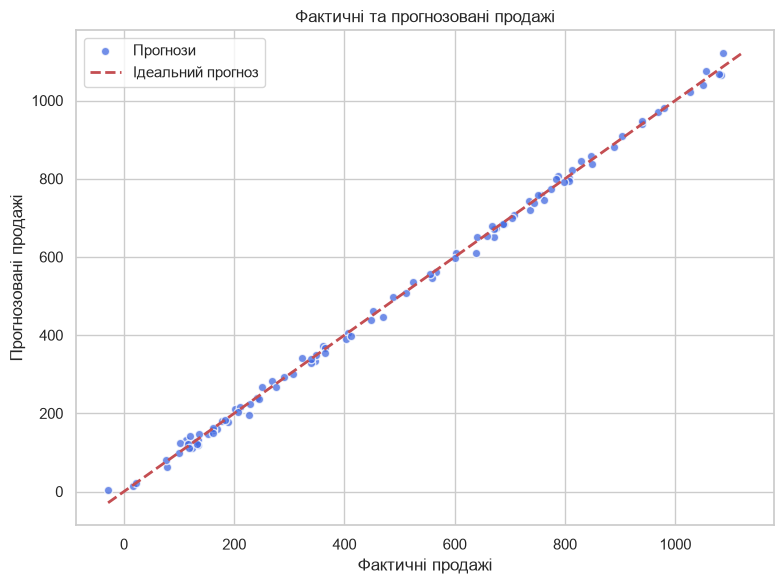

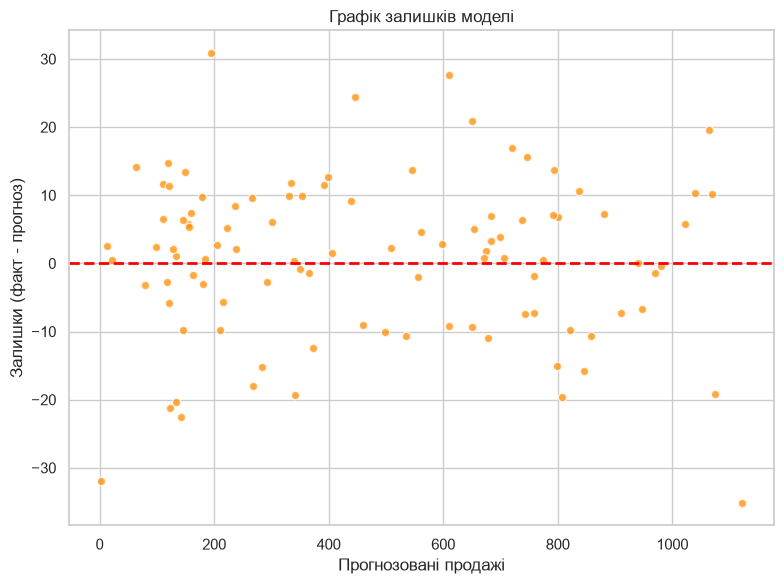

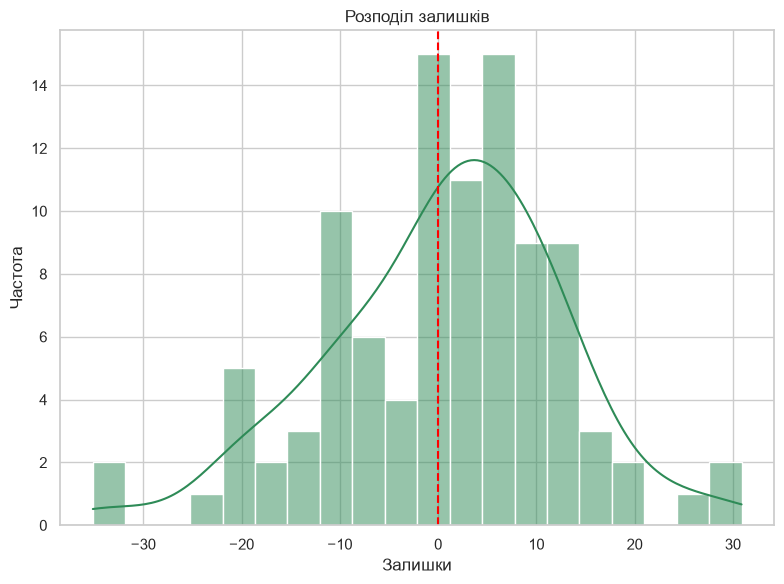

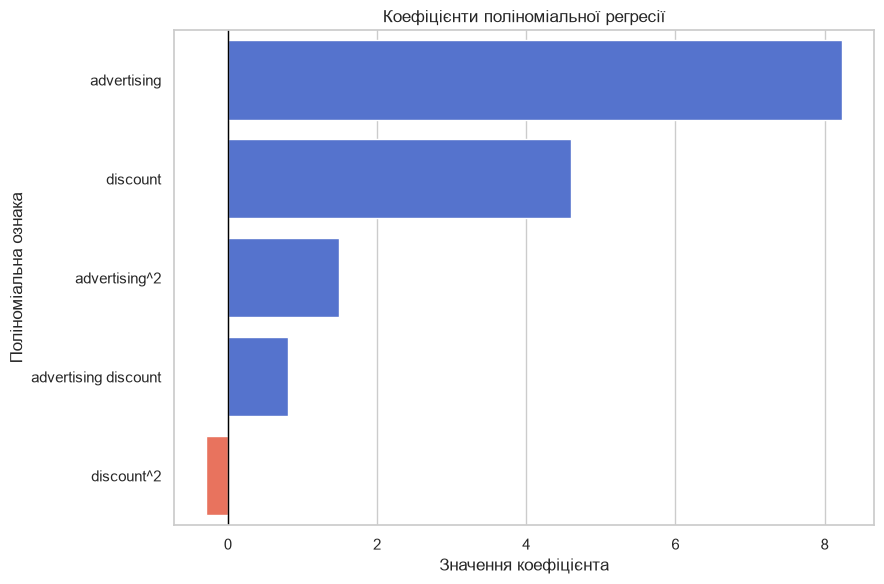

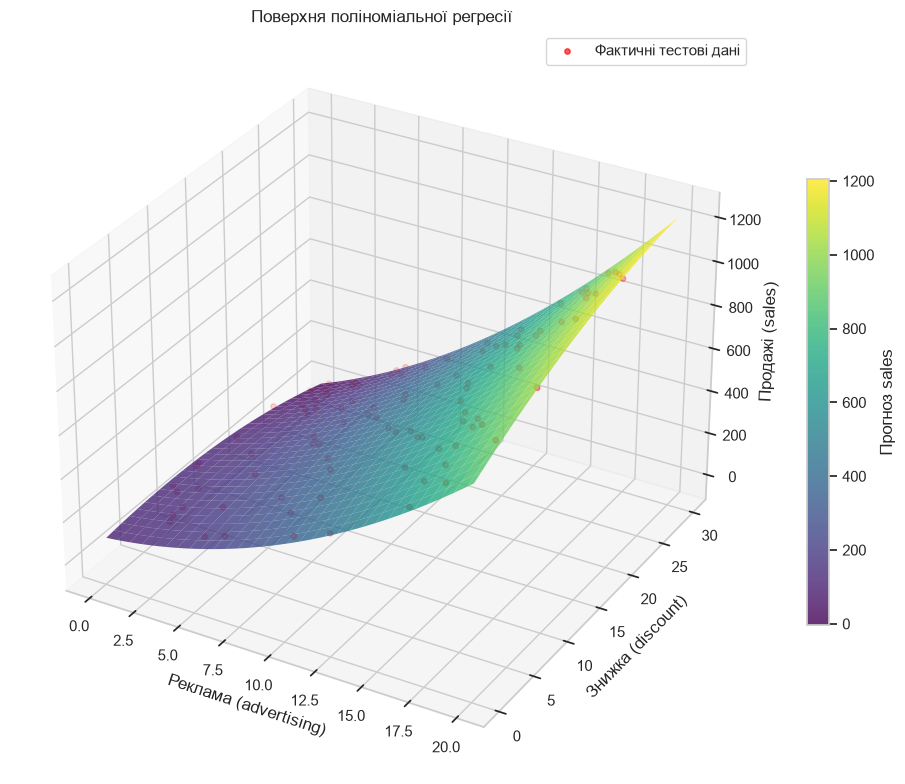


ПІДСУМОК
R² на тестових даних: 0.9985
MAE:  9.2403
MSE:  141.0979
RMSE: 11.8785
MAPE: 4.36%

Збережені файли:
- regression_metrics.csv
- regression_predictions.csv
- 01_actual_vs_predicted.png
- 02_residuals.png
- 03_residual_distribution.png
- 04_model_coefficients.png
- 05_regression_surface.png


In [18]:
# ------------------------------------------------------------
# 4. Розрахунок метрик якості
# ------------------------------------------------------------
 
def calculate_metrics(y_true, y_pred, n_features):
    n = len(y_true)
 
    r2 = r2_score(y_true, y_pred)
 
    # Скоригований коефіцієнт детермінації
    adjusted_r2 = (
        1 - (1 - r2) * (n - 1) / (n - n_features - 1)
        if n > n_features + 1 else np.nan
    )
 
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
 
    return {
        "R²": r2,
        "Скоригований R²": adjusted_r2,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": rmse,
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100,
        "Медіанна абсолютна похибка": median_absolute_error(
            y_true, y_pred
        ),
        "Максимальна абсолютна похибка": max_error(
            y_true, y_pred
        ),
        "Explained Variance": explained_variance_score(
            y_true, y_pred
        )
    }
 
# У моделі другого ступеня 5 ознак:
# advertising, discount, advertising², discount²,
# advertising × discount
n_features = 5
 
metrics_train = calculate_metrics(
    y_train, y_train_pred, n_features
)
 
metrics_test = calculate_metrics(
    y_test, y_pred, n_features
)
 
metrics_df = pd.DataFrame({
    "Навчальна вибірка": metrics_train,
    "Тестова вибірка": metrics_test
})
 
print("\n" + "=" * 65)
print("МЕТРИКИ ЯКОСТІ МОДЕЛІ")
print("=" * 65)
print(metrics_df.round(4).to_string())
 
metrics_df.to_csv("regression_metrics.csv", encoding="utf-8-sig")
 
# ------------------------------------------------------------
# 5. Коефіцієнти та рівняння регресії
# ------------------------------------------------------------
 
poly = model.named_steps["poly"]
reg = model.named_steps["regression"]
 
feature_names = poly.get_feature_names_out(X.columns)
 
print("\nРІВНЯННЯ ПОЛІНОМІАЛЬНОЇ РЕГРЕСІЇ:")
print(f"sales = {reg.intercept_:.4f}")
 
for name, coef in zip(feature_names, reg.coef_):
    sign = "+" if coef >= 0 else "-"
    print(f"  {sign} {abs(coef):.4f} * {name}")
 
coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": reg.coef_
})
 
# ------------------------------------------------------------
# 6. Таблиця фактичних і прогнозованих значень
# ------------------------------------------------------------
 
results = X_test.copy()
results["Фактичні продажі"] = y_test
results["Прогнозовані продажі"] = y_pred
results["Залишок"] = y_test.to_numpy() - y_pred
results["Абсолютна похибка"] = np.abs(results["Залишок"])
 
print("\nПОРІВНЯННЯ ФАКТИЧНИХ І ПРОГНОЗОВАНИХ ПРОДАЖІВ:")
print(results.head(10).round(3).to_string())
 
results.to_csv(
    "regression_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)
 
# ------------------------------------------------------------
# 7. Графік 1: фактичні проти прогнозованих продажів
# ------------------------------------------------------------
 
sns.set_theme(style="whitegrid")
 
plt.figure(figsize=(8, 6))
 
plt.scatter(
    y_test, y_pred,
    alpha=0.75,
    color="royalblue",
    edgecolor="white",
    label="Прогнози"
)
 
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
 
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2,
    label="Ідеальний прогноз"
)
 
plt.xlabel("Фактичні продажі")
plt.ylabel("Прогнозовані продажі")
plt.title("Фактичні та прогнозовані продажі")
plt.legend()
plt.tight_layout()
plt.savefig("01_actual_vs_predicted.png", dpi=300)
plt.show()
 
# ------------------------------------------------------------
# 8. Графік 2: аналіз залишків
# ------------------------------------------------------------
 
residuals = y_test.to_numpy() - y_pred
 
plt.figure(figsize=(8, 6))
 
plt.scatter(
    y_pred, residuals,
    alpha=0.75,
    color="darkorange",
    edgecolor="white"
)
 
plt.axhline(0, color="red", linestyle="--", linewidth=2)
 
plt.xlabel("Прогнозовані продажі")
plt.ylabel("Залишки (факт - прогноз)")
plt.title("Графік залишків моделі")
plt.tight_layout()
plt.savefig("02_residuals.png", dpi=300)
plt.show()
 
# ------------------------------------------------------------
# 9. Графік 3: розподіл залишків
# ------------------------------------------------------------
 
plt.figure(figsize=(8, 6))
 
sns.histplot(
    residuals,
    kde=True,
    color="seagreen",
    bins=20
)
 
plt.axvline(0, color="red", linestyle="--")
 
plt.xlabel("Залишки")
plt.ylabel("Частота")
plt.title("Розподіл залишків")
plt.tight_layout()
plt.savefig("03_residual_distribution.png", dpi=300)
plt.show()
 
# ------------------------------------------------------------
# 10. Графік 4: коефіцієнти поліноміальної моделі
# ------------------------------------------------------------
 
plt.figure(figsize=(9, 6))
 
colors = [
    "royalblue" if c >= 0 else "tomato"
    for c in coef_df["Коефіцієнт"]
]
 
sns.barplot(
    data=coef_df,
    x="Коефіцієнт",
    y="Ознака",
    hue="Ознака",
    palette=colors,
    legend=False
)
 
plt.axvline(0, color="black", linewidth=1)
plt.title("Коефіцієнти поліноміальної регресії")
plt.xlabel("Значення коефіцієнта")
plt.ylabel("Поліноміальна ознака")
plt.tight_layout()
plt.savefig("04_model_coefficients.png", dpi=300)
plt.show()
 
# ------------------------------------------------------------
# 11. Графік 5: поверхня прогнозованих продажів
# ------------------------------------------------------------
 
advertising_range = np.linspace(
    X["advertising"].min(),
    X["advertising"].max(),
    60
)
 
discount_range = np.linspace(
    X["discount"].min(),
    X["discount"].max(),
    60
)
 
A, D = np.meshgrid(advertising_range, discount_range)
 
grid = pd.DataFrame({
    "advertising": A.ravel(),
    "discount": D.ravel()
})
 
Z = model.predict(grid).reshape(A.shape)
 
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
 
surface = ax.plot_surface(
    A, D, Z,
    cmap="viridis",
    alpha=0.8,
    edgecolor="none"
)
 
ax.scatter(
    X_test["advertising"],
    X_test["discount"],
    y_test,
    color="red",
    s=15,
    alpha=0.65,
    label="Фактичні тестові дані"
)
 
ax.set_xlabel("Реклама (advertising)")
ax.set_ylabel("Знижка (discount)")
ax.set_zlabel("Продажі (sales)")
ax.set_title("Поверхня поліноміальної регресії")
ax.legend()
 
fig.colorbar(surface, ax=ax, shrink=0.6, label="Прогноз sales")
plt.tight_layout()
plt.savefig("05_regression_surface.png", dpi=300)
plt.show()
 
# ------------------------------------------------------------
# 12. Підсумок
# ------------------------------------------------------------
 
print("\n" + "=" * 65)
print("ПІДСУМОК")
print("=" * 65)
 
print(f"R² на тестових даних: {metrics_test['R²']:.4f}")
print(f"MAE:  {metrics_test['MAE']:.4f}")
print(f"MSE:  {metrics_test['MSE']:.4f}")
print(f"RMSE: {metrics_test['RMSE']:.4f}")
print(f"MAPE: {metrics_test['MAPE (%)']:.2f}%")
 
print("\nЗбережені файли:")
print("- regression_metrics.csv")
print("- regression_predictions.csv")
print("- 01_actual_vs_predicted.png")
print("- 02_residuals.png")
print("- 03_residual_distribution.png")
print("- 04_model_coefficients.png")
print("- 05_regression_surface.png")